In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
from plot_config import COLORS, FIG_W_SINGLE, FIG_W_DOUBLE, set_font_size
GRID = False
FONT_SIZE = 18
set_font_size(FONT_SIZE)

# Disturbance Rejection vs Spring Constant

`disturbance_k3_100.npz` — a single spring (1 VC, s=1.0 end-effector) under an impulse
torque disturbance on x, for each k ∈ [3, 100] N/m. Step/impulse disturbance-rejection
characterization (peak overshoot, settling time, ringing), not sustained forced oscillation.

**Setup:**
```
Terminal 1: bash start_arm.sh
Terminal 2: cd LinearSpring && python3 ../VMC/GUI_MultiVMC_Torque.py
Terminal 3: cd LinearSpring && python3 ../VMC/GUI_MultiVMC.py
```

**Procedure per k:** set k in the GUI, apply an x-torque disturbance from terminal 4
(`ros2 topic pub -r 200 -t 100 /goal_torque std_msgs/msg/Float64MultiArray "data: [-0.3, 0.0,
0.0, -0.3, 0.0, -0.3, 0.0, 0.0, 0.0]"`), snap back to origin with k=690, increment k by 30 and
repeat. Above k≈300 the snap-back isn't needed.

**Goal:** overlay all disturbance responses aligned to t=0 at onset, colored by k (blue→red).

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Load main dataset
NPZ = 'outputs/disturbance_rejection/disturbance_k3_100.npz'
d = np.load(NPZ)

# Load the re-run data for the k=13/20 points (
# filename unchanged) -- a cleaner redo of two glitchy points from the main sweep
NPZ_CORRECTED = 'outputs/disturbance_rejection/disturbance_k13_20.npz'
d_corrected = np.load(NPZ_CORRECTED)

# Extract main arrays
t        = d['t']
x        = d['comp_pos'][:, 0, 0]      # end-effector x [m]
k_t      = d['k_params'][:, 0]         # k over time
goal_x   = d['goal'][:, 0, 0]          # reference x
fs       = float(d['control_freq'][0])

print(f"Main file: Duration: {t[-1]-t[0]:.1f} s   n={len(t)}   fs={fs:.0f} Hz")
print(f"Corrected file: {d_corrected['t'][-1] - d_corrected['t'][0]:.1f} s, n={len(d_corrected['t'])}")

# Store re-run data for the two re-run stiffness points
d_corrected_k40_idx = np.where(np.abs(d_corrected['k_params'][:, 0] - 13.333) < 0.5)[0]
d_corrected_k50_idx = np.where(np.abs(d_corrected['k_params'][:, 0] - 16.667) < 0.5)[0]

print(f"Corrected k=13 samples: {len(d_corrected_k40_idx)}   k=20 samples: {len(d_corrected_k50_idx)}")
print(f"Original k unique: {np.unique(np.round(k_t, 1))}")
print(f"x range: [{x.min():.4f}, {x.max():.4f}] m")

Main file: Duration: 296.9 s   n=97932   fs=330 Hz
Corrected file: 47.2 s, n=15581
Corrected k=13 samples: 5368   k=20 samples: 6289
Original k unique: [  0.    3.3   6.7  10.   13.3  16.7  20.   23.3  26.7  30.   33.3  36.7
  40.   43.3  46.7  50.   53.3  56.7  60.   63.3  66.7  70.   73.3  76.7
  80.   83.3  86.7  90.   93.3  96.7 100. ]
x range: [-0.0278, 0.0806] m


In [3]:
# Segment data by constant k
changes = np.where(np.diff(k_t) != 0)[0] + 1
starts  = np.concatenate([[0], changes])
ends    = np.concatenate([changes, [len(k_t)]])
segs    = [(s, e, float(k_t[s])) for s, e in zip(starts, ends)]

# For k < 300: exclude snap-back phases (k > 600)
# For k >= 300: keep all data
test_segs = [seg for seg in segs if seg[2] not in [600, 690, 750]]
k_values = sorted({seg[2] for seg in test_segs})

print(f"Test segments (excluding snap-back k values): {len(test_segs)}")
print(f"k values to plot: {[round(v, 1) for v in k_values]}")
for s, e, k in test_segs[:5]:
    print(f"  k={k:>5.0f}   t=[{t[s]:6.2f}, {t[e-1]:6.2f}] s   n={e-s}")

Test segments (excluding snap-back k values): 36
k values to plot: [0.0, 3.3, 6.7, 10.0, 13.3, 16.7, 20.0, 23.3, 26.7, 30.0, 33.3, 36.7, 40.0, 43.3, 46.7, 50.0, 53.3, 56.7, 60.0, 63.3, 66.7, 70.0, 73.3, 76.7, 80.0, 83.3, 86.7, 90.0, 93.3, 96.7, 100.0]
  k=    0   t=[  0.00,  12.70] s   n=4190
  k=    3   t=[ 12.70,  25.83] s   n=4335
  k=   77   t=[ 25.84,  31.50] s   n=1869
  k=    7   t=[ 31.50,  44.48] s   n=4286
  k=   77   t=[ 44.49,  48.68] s   n=1383


## Detect disturbance onset for each k

The disturbance causes the robot to suddenly move in +x. We detect onset by finding when |x| exceeds a threshold (e.g., 0.5 mm) — before that, the robot sits at rest near x=0.

In [4]:
def find_disturbance_onset(x_seg, min_samples=10):
    """Find onset by detecting where x starts consistently increasing.
    
    Look for a sequence of positive derivatives indicating disturbance push has begun.
    """
    dx = np.diff(x_seg)
    # Find the first point where derivatives are consistently positive
    for i in range(len(dx) - min_samples):
        if np.all(dx[i:i+min_samples] > 0):  # all derivatives in window are positive
            return i
    return -1

responses = {}
for k in k_values:
    # Use re-run data for those two stiffness points; otherwise the main dataset
    if abs(k - 13.333) < 0.5:
        if len(d_corrected_k40_idx) > 0:
            x_seg = d_corrected['comp_pos'][d_corrected_k40_idx, 0, 0]
            t_seg = d_corrected['t'][d_corrected_k40_idx]
        else:
            continue
    elif abs(k - 16.667) < 0.5:
        if len(d_corrected_k50_idx) > 0:
            x_seg = d_corrected['comp_pos'][d_corrected_k50_idx, 0, 0]
            t_seg = d_corrected['t'][d_corrected_k50_idx]
        else:
            continue
    else:
        seg = [s for s in test_segs if s[2] == k][0]
        s, e, _ = seg
        x_seg = x[s:e]
        t_seg = t[s:e]
    
    onset_idx = find_disturbance_onset(x_seg, min_samples=10)
    
    if onset_idx >= 0:
        max_duration = 5.0
        max_samples = int(max_duration * fs)
        end_idx = min(onset_idx + max_samples, len(x_seg))
        
        x_resp = x_seg[onset_idx:end_idx]
        t_resp = t_seg[onset_idx:end_idx] - t_seg[onset_idx]
        
        # Find peak and its time
        peak_idx = np.argmax(np.abs(x_resp))
        peak_val = x_resp[peak_idx]
        peak_time = t_resp[peak_idx]
        
        responses[k] = (t_resp, x_resp)
        print(f"k={k:>5.0f}: peak={1000*peak_val:>7.2f}mm @ t={peak_time:.3f}s")

print(f"\nTotal responses extracted: {len(responses)}")

k=    3: peak=  80.60mm @ t=0.555s
k=    7: peak=  76.13mm @ t=0.545s
k=   10: peak=  69.58mm @ t=0.536s
k=   13: peak=  72.21mm @ t=0.533s
k=   17: peak=  65.63mm @ t=0.533s
k=   20: peak=  67.28mm @ t=0.521s
k=   23: peak=  47.68mm @ t=0.521s
k=   27: peak=  54.09mm @ t=0.515s
k=   30: peak=  50.77mm @ t=0.515s
k=   33: peak=  50.18mm @ t=0.516s
k=   37: peak=  44.65mm @ t=0.421s
k=   40: peak=  41.31mm @ t=0.460s
k=   43: peak=  44.99mm @ t=0.509s
k=   47: peak=  47.16mm @ t=0.503s
k=   50: peak=  48.53mm @ t=0.515s
k=   53: peak=  46.26mm @ t=0.424s
k=   57: peak=  43.75mm @ t=0.367s
k=   60: peak=  51.31mm @ t=0.461s
k=   63: peak=  49.27mm @ t=0.472s
k=   67: peak=  47.02mm @ t=0.503s
k=   70: peak=  46.59mm @ t=0.449s
k=   73: peak=  39.30mm @ t=0.493s
k=   77: peak= -16.38mm @ t=0.000s
k=   80: peak=  41.11mm @ t=0.348s
k=   87: peak=  40.95mm @ t=0.337s
k=   90: peak=  38.19mm @ t=0.497s
k=   93: peak=  39.44mm @ t=0.491s
k=   97: peak=  39.71mm @ t=0.318s
k=  100: peak=  34.4

## Plot: Disturbance response overlay (time-aligned, colored by k)

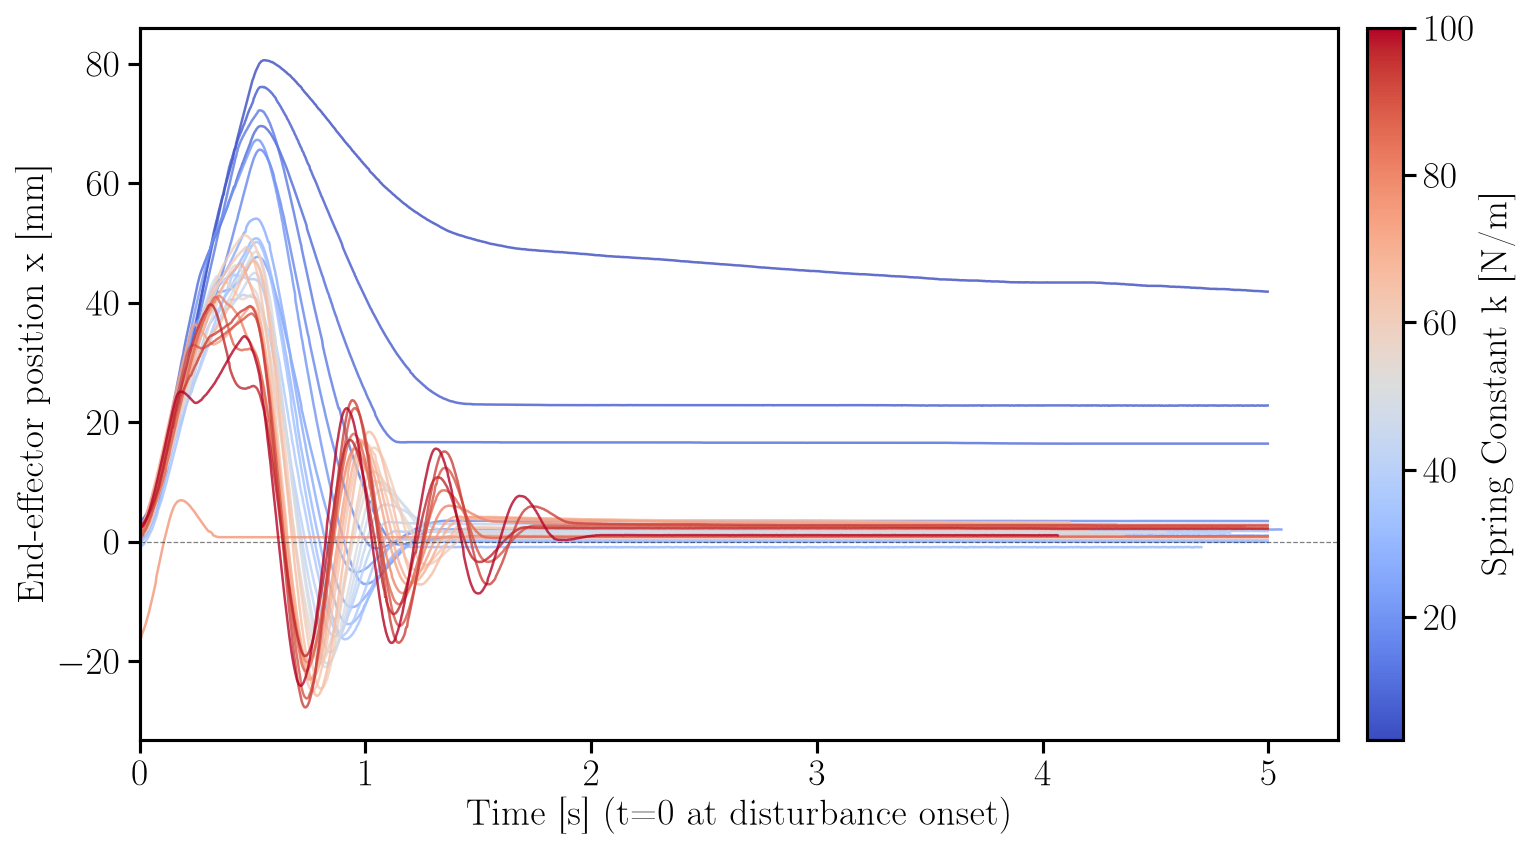

✓ Lower k → softer, larger overshoot. Higher k → stiffer, less overshoot.


In [5]:
# ---- size / aspect for THIS graph only ----
W_IN   = 11.0   # inches -- width; the deliberate choice, so the fixed 18pt font
                # reads at the intended size once this is fixed
ASPECT = 6 / 11
H_IN   = W_IN * ASPECT

fig, ax = plt.subplots(figsize=(W_IN, H_IN))

cmap = plt.colormaps['coolwarm']
k_min, k_max = min(responses.keys()), max(responses.keys())
norm = plt.Normalize(vmin=k_min, vmax=k_max)

for k in sorted(responses.keys()):
    t_resp, x_resp = responses[k]
    color = cmap(norm(k))
    ax.plot(t_resp, 1000 * x_resp, linewidth=1.2, alpha=0.8, color=color, label=f'K = {k:.0f}')

ax.axhline(0, color='black', linewidth=0.6, linestyle='--', alpha=0.5)
ax.set_xlabel('Time [s] (t=0 at disturbance onset)')
ax.set_ylabel('End-effector position x [mm]')
ax.set_xlim(0, None)
ax.grid(GRID)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label('Spring Constant k [N/m]')

plt.tight_layout()
plt.savefig(os.path.join('outputs', 'disturbance_rejection', 'disturbance_response_by_k.pdf'))
plt.show()

print("✓ Lower k → softer, larger overshoot. Higher k → stiffer, less overshoot.")